## Geldium: Credit Delinquency Prediction

**Models:** Logistic Regression and Decision Tree  
**Goal:** Predict whether a customer may become delinquent using the cleaned customer dataset.

This notebook:
1. Loads and checks the cleaned data.
2. Selects relevant input features.
3. Splits the data into training and testing sets.
4. Trains Logistic Regression and Decision Tree models.
5. Compares their performance.
6. Checks performance across selected customer groups.
7. Shows how to predict risk for a new customer.


1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

2. Load the cleaned dataset

In [2]:
df = pd.read_excel("Delinquency_Prediction_Cleaned.xlsx")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (500, 30)


,Customer_ID,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Employment_Status,...,Credit_Score_Imputed,Income_Imputed,Utilization_Imputed,Late_Payment_Count,Missed_Payment_Count,On_Time_Payment_Count,Utilization_Group,Missed_Months,Late_Months,On_Time_Months
0,CUST0001,56,165580.0,398,0.390502,3,0,16310,0.317396,employed,...,0,0,0,4,2,0,25-50%,2,4,0
1,CUST0002,69,100999.0,493,0.312444,6,1,17401,0.196093,self-employed,...,0,0,0,1,3,2,25-50%,3,1,2
2,CUST0003,46,188416.0,500,0.359930,0,0,13761,0.301655,self-employed,...,0,0,0,3,2,1,25-50%,2,3,1
3,CUST0004,32,101672.0,413,0.371400,3,0,88778,0.264794,unemployed,...,0,0,0,4,2,0,25-50%,2,4,0
4,CUST0005,60,38524.0,487,0.234716,2,0,13316,0.510583,self-employed,...,0,0,0,3,2,1,0-25%,2,3,1


3. Check the target and data

In [3]:
target = "Delinquent_Account"

print("Columns:")
print(df.columns.tolist())

print("\\nTarget counts:")
print(df[target].value_counts(dropna=False))

print("\\nMissing values in selected columns:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

Columns:
['Customer_ID', 'Age', 'Income', 'Credit_Score', 'Credit_Utilization', 'Missed_Payments', 'Delinquent_Account', 'Loan_Balance', 'Debt_to_Income_Ratio', 'Employment_Status', 'Account_Tenure', 'Credit_Card_Type', 'Location', 'Month_1', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Loan_Balance_Imputed', 'Credit_Score_Imputed', 'Income_Imputed', 'Utilization_Imputed', 'Late_Payment_Count', 'Missed_Payment_Count', 'On_Time_Payment_Count', 'Utilization_Group', 'Missed_Months', 'Late_Months', 'On_Time_Months']
\nTarget counts:
Delinquent_Account
0    420
1     80
Name: count, dtype: int64
\nMissing values in selected columns:


Customer_ID             0
Age                     0
Income                  0
Credit_Score            0
Credit_Utilization      0
Missed_Payments         0
Delinquent_Account      0
Loan_Balance            0
Debt_to_Income_Ratio    0
Employment_Status       0
dtype: int64

4. Select input features

In [4]:
features = [
    "Income",
    "Credit_Utilization",
    "Missed_Payments",
    "Debt_to_Income_Ratio",
    "Account_Tenure"
]

# Keep only the selected input features and target.
data = df[features + [target]].copy()

# Remove rows where the target is missing.
data = data.dropna(subset=[target])

X = data[features]
y = data[target].astype(int)

print("Feature columns:", features)
print("Target distribution:")
display(y.value_counts())
print("Delinquency rate:", round(y.mean() * 100, 2), "%")

Feature columns: ['Income', 'Credit_Utilization', 'Missed_Payments', 'Debt_to_Income_Ratio', 'Account_Tenure']
Target distribution:


Delinquent_Account
0    420
1     80
Name: count, dtype: int64

Delinquency rate: 16.0 %


5. Split into training and testing data

We keep 20% of the data for final testing. `stratify=y` keeps a similar proportion of delinquent and non-delinquent customers in both sets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\\nTraining target distribution:")
display(y_train.value_counts(normalize=True).rename("proportion"))

Training rows: 400
Testing rows: 100
\nTraining target distribution:


Delinquent_Account
0    0.84
1    0.16
Name: proportion, dtype: float64

6. Prepare preprocessing steps

Missing numeric values are filled using the median calculated from the training data. Logistic Regression also needs feature scaling; Decision Trees do not, so we use separate pipelines.

In [6]:
# Logistic Regression: median imputation + standardization
lr_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Decision Tree: median imputation only
tree_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

7. Build and train both models

Class weighting helps the models pay more attention to the minority delinquent class. The Decision Tree is limited in depth to reduce the risk of overfitting.

In [7]:
logistic_model = Pipeline([
    ("preprocessing", lr_preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

tree_model = Pipeline([
    ("preprocessing", tree_preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

print("Both models have been trained.")

Both models have been trained.


8. Evaluate model performance

In [8]:
def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "PR_AUC": average_precision_score(y_test, probabilities)
    }

    return results

lr_results = evaluate_model("Logistic Regression", logistic_model, X_test, y_test)
tree_results = evaluate_model("Decision Tree", tree_model, X_test, y_test)

comparison = pd.DataFrame([lr_results, tree_results]).set_index("Model")
display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
Logistic Regression,0.46,0.135,0.438,0.206,0.449,0.192
Decision Tree,0.66,0.179,0.312,0.227,0.500,0.168


9. Confusion matrices and classification reports

The confusion matrix shows correct and incorrect predictions. In particular:
- **False Negative:** an actually delinquent customer predicted as non-delinquent.
- **False Positive:** a non-delinquent customer predicted as delinquent.

\n Logistic Regression
                precision    recall  f1-score   support

Non-delinquent       0.81      0.46      0.59        84
    Delinquent       0.13      0.44      0.21        16

      accuracy                           0.46       100
     macro avg       0.47      0.45      0.40       100
  weighted avg       0.70      0.46      0.53       100



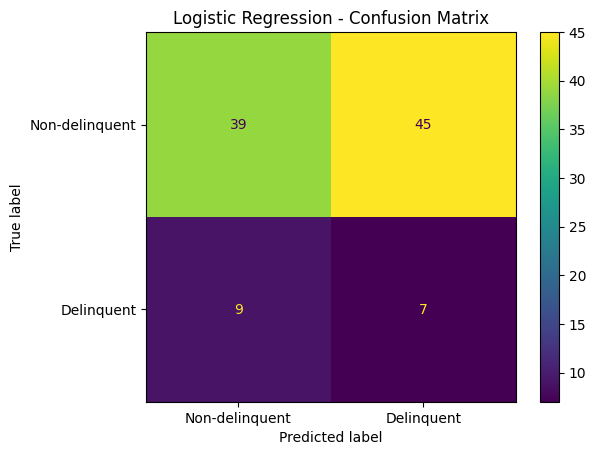

\n Decision Tree
                precision    recall  f1-score   support

Non-delinquent       0.85      0.73      0.78        84
    Delinquent       0.18      0.31      0.23        16

      accuracy                           0.66       100
     macro avg       0.51      0.52      0.50       100
  weighted avg       0.74      0.66      0.69       100



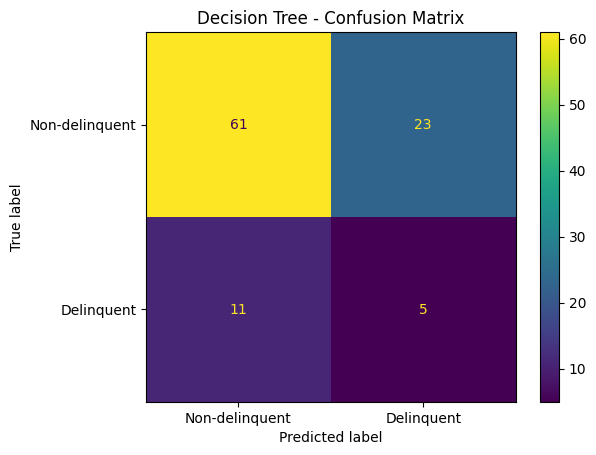

In [9]:
for name, model in [
    ("Logistic Regression", logistic_model),
    ("Decision Tree", tree_model)
]:
    print("\\n", name)
    predictions = model.predict(X_test)

    print(classification_report(
        y_test,
        predictions,
        target_names=["Non-delinquent", "Delinquent"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Non-delinquent", "Delinquent"],
        values_format="d"
    )
    plt.title(name + " - Confusion Matrix")
    plt.show()

10. Compare ROC curves

The ROC curve compares true-positive and false-positive rates across different classification thresholds. A higher ROC-AUC generally indicates better separation between the two classes.

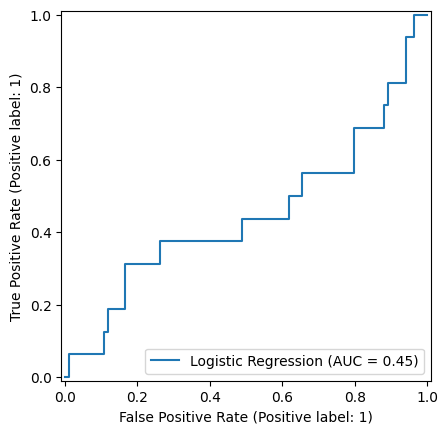

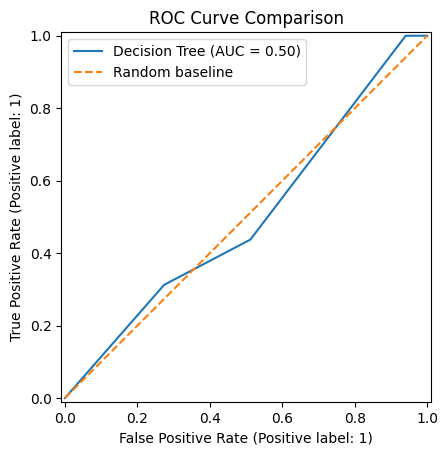

In [10]:
RocCurveDisplay.from_estimator(logistic_model, X_test, y_test, name="Logistic Regression")
RocCurveDisplay.from_estimator(tree_model, X_test, y_test, name="Decision Tree")

plt.plot([0,  1], [0, 1], linestyle="--", label="Random baseline")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

11. Cross-validation check

A single train-test split can give a noisy estimate on a small dataset. Stratified 5-fold cross-validation provides an additional check of F1 consistency using the training data only.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_cv_scores = cross_val_score(
    logistic_model, X_train, y_train, cv=cv, scoring="f1"
)
tree_cv_scores = cross_val_score(
    tree_model, X_train, y_train, cv=cv, scoring="f1"
)

print("Logistic Regression CV F1:", np.round(lr_cv_scores, 3))
print("Mean:", round(lr_cv_scores.mean(), 3), " Std:", round(lr_cv_scores.std(), 3))

print("\\nDecision Tree CV F1:", np.round(tree_cv_scores, 3))
print("Mean:", round(tree_cv_scores.mean(), 3), " Std:", round(tree_cv_scores.std(), 3))

Logistic Regression CV F1: [0.255 0.267 0.37  0.327 0.259]
Mean: 0.296  Std: 0.045
\nDecision Tree CV F1: [0.267 0.246 0.304 0.231 0.254]
Mean: 0.26  Std: 0.025


12. Inspect feature importance

Logistic Regression coefficients show the direction and size of each feature's relationship with the predicted delinquency class after scaling. Decision Tree feature importance shows how much each feature contributed to the tree's splits.

These are model explanations, not proof that a feature causes delinquency.

,Feature,Coefficient
1,Credit_Utilization,0.131193
0,Income,0.116839
3,Debt_to_Income_Ratio,0.111590
4,Account_Tenure,-0.157099
2,Missed_Payments,-0.157263


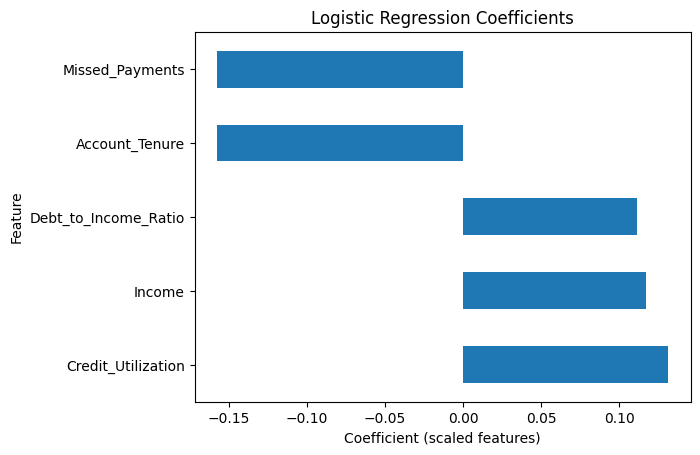

,Feature,Importance
1,Credit_Utilization,0.496443
0,Income,0.273139
4,Account_Tenure,0.166943
3,Debt_to_Income_Ratio,0.063475
2,Missed_Payments,0.000000


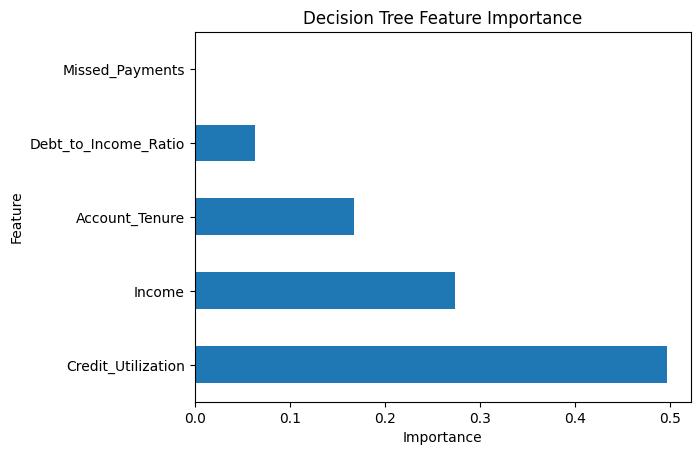

In [12]:
# Logistic Regression coefficients
lr_coefficients = logistic_model.named_steps["model"].coef_[0]

lr_importance = pd.DataFrame({
    "Feature": features,
    "Coefficient": lr_coefficients
}).sort_values("Coefficient", ascending=False)

display(lr_importance)

lr_importance.set_index("Feature")["Coefficient"].plot(kind="barh")
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient (scaled features)")
plt.show()

# Decision Tree feature importance
tree_importance = pd.DataFrame({
    "Feature": features,
    "Importance": tree_model.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)

display(tree_importance)

tree_importance.set_index("Feature")["Importance"].plot(kind="barh")
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.show()

13. Visualize the Decision Tree

The tree diagram shows the decision rules learned from the training data. We display feature names and class names to make the branches easier to read.

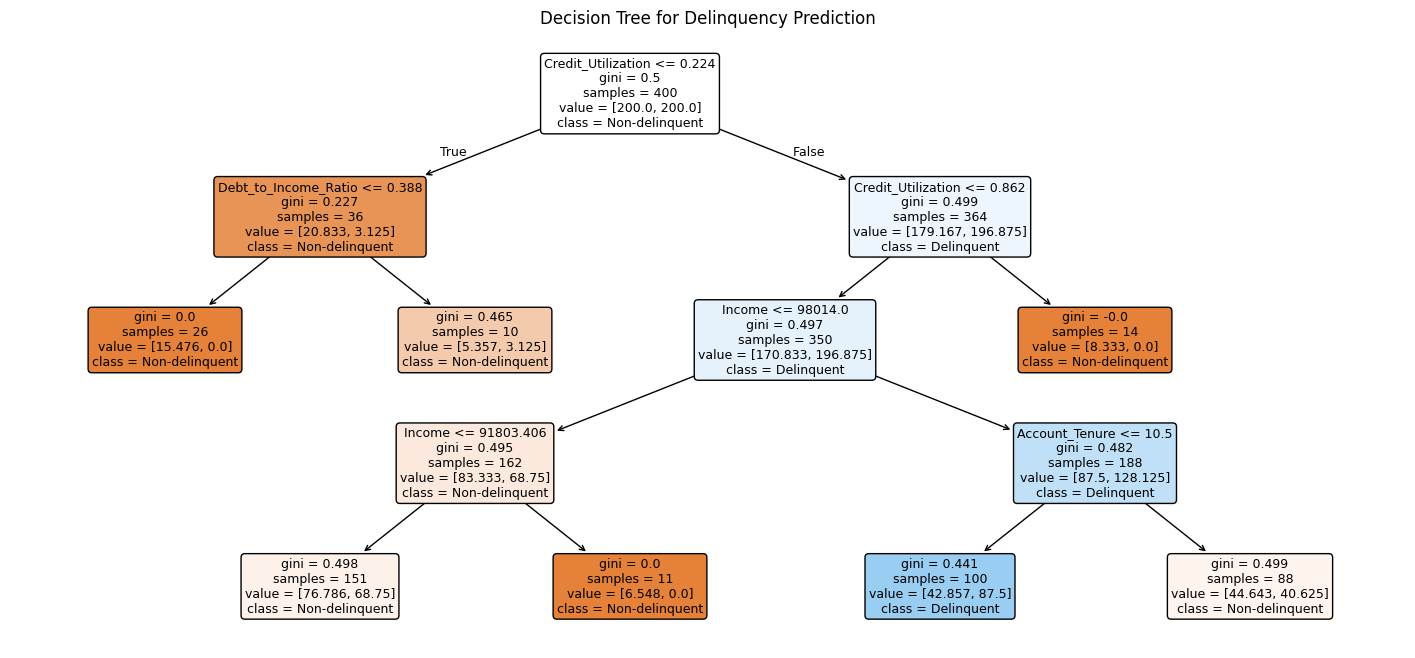

In [13]:
plt.figure(figsize=(18, 8))

plot_tree(
    tree_model.named_steps["model"],
    feature_names=features,
    class_names=["Non-delinquent", "Delinquent"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree for Delinquency Prediction")
plt.show()

14. Basic fairness check by customer group

This section compares recall and false-positive rate across groups such as employment status and location, if those columns are available. It uses the test set only.

**Important:** Group metrics can be unreliable when a group has very few customers. Review group counts and confidence intervals before drawing conclusions. A difference is a signal to investigate, not proof of discrimination.

In [14]:
def group_fairness_report(model, X_test, y_test, group_values, group_name):
    predictions = model.predict(X_test)

    report_data = pd.DataFrame({
        "Actual": y_test,
        "Predicted": predictions,
        "Group": group_values
    }).dropna()

    rows = []

    for group, part in report_data.groupby("Group"):
        actual = part["Actual"]
        predicted = part["Predicted"]

        tp = ((actual == 1) & (predicted == 1)).sum()
        fn = ((actual == 1) & (predicted == 0)).sum()
        fp = ((actual == 0) & (predicted == 1)).sum()
        tn = ((actual == 0) & (predicted == 0)).sum()

        recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        positive_rate = predicted.mean()

        rows.append({
            group_name: group,
            "Customers": len(part),
            "Actual_Delinquent": int(actual.sum()),
            "Recall": recall,
            "False_Positive_Rate": fpr,
            "Predicted_Positive_Rate": positive_rate
        })

    return pd.DataFrame(rows)

# Try employment status and location when available.
for group_column in ["Employment_Status", "Location"]:
    if group_column in df.columns:
        test_group_values = df.loc[X_test.index, group_column]
        print("\\nFairness check by", group_column)
        display(
            group_fairness_report(
                logistic_model, X_test, y_test,
                test_group_values, group_column
            ).round(3)
        )
    else:
        print(group_column, "not found; skipping this group check.")

\nFairness check by Employment_Status


,Employment_Status,Customers,Actual_Delinquent,Recall,False_Positive_Rate,Predicted_Positive_Rate
0,employed,42,6,0.667,0.556,0.571
1,retired,18,0,NaN,0.500,0.500
2,self-employed,16,4,0.000,0.500,0.375
3,unemployed,24,6,0.500,0.556,0.542


\nFairness check by Location


,Location,Customers,Actual_Delinquent,Recall,False_Positive_Rate,Predicted_Positive_Rate
0,Chicago,20,2,0.000,0.556,0.500
1,Houston,14,2,0.500,0.583,0.571
2,Los Angeles,26,6,0.667,0.550,0.577
3,New York,17,2,0.500,0.533,0.529
4,Phoenix,23,4,0.250,0.474,0.435


15. Predict delinquency risk for a new customer

Enter example values using the same units and conventions as the dataset. The model returns a probability and a class prediction. The 0.50 threshold is only a starting point and should be selected using validation results and business costs.

In [15]:
new_customer = pd.DataFrame([{
    "Income": 60000,
    "Credit_Utilization": 75,
    "Missed_Payments": 4,
    "Debt_to_Income_Ratio": 35,
    "Account_Tenure": 2
}])

# Logistic Regression prediction
lr_probability = logistic_model.predict_proba(new_customer)[0, 1]
lr_prediction = logistic_model.predict(new_customer)[0]

print("Logistic Regression")
print("Delinquency probability:", round(lr_probability * 100, 2), "%")
print("Predicted class:", "Delinquent" if lr_prediction == 1 else "Non-delinquent")

# Decision Tree prediction
tree_probability = tree_model.predict_proba(new_customer)[0, 1]
tree_prediction = tree_model.predict(new_customer)[0]

print("\\nDecision Tree")
print("Delinquency probability:", round(tree_probability * 100, 2), "%")
print("Predicted class:", "Delinquent" if tree_prediction == 1 else "Non-delinquent")

Logistic Regression
Delinquency probability: 100.0 %
Predicted class: Delinquent
\nDecision Tree
Delinquency probability: 0.0 %
Predicted class: Non-delinquent


## 16. Final comparison and conclusion

Use the test metrics and cross-validation results to decide which model is more suitable. Do not select a model based on accuracy alone.

For Geldium:
- Consider recall because missing a genuinely at-risk customer may delay useful support.
- Consider precision because false alarms can lead to unnecessary customer contact.
- Review PR-AUC because delinquent customers are the minority class.
- Review fairness results and calibration before any operational use.
- Keep predictions as decision-support information, with appropriate human review.

**Note:** This dataset is small, so results are preliminary. Before deployment, validate the target definition and prediction time window, check for data leakage, assess probability calibration, and test the model on newer data.